In [1]:
print("AI-Based Student Performance Prediction System")
print("Project setup started successfully!")

AI-Based Student Performance Prediction System
Project setup started successfully!


In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
import pandas as pd

data = {
    "StudyHours": [1, 2, 3, 4, 5, 6, 7, 8, 2, 4, 6, 9, 3, 5, 7],
    "Attendance": [50, 55, 65, 70, 75, 80, 85, 95, 60, 72, 88, 98, 62, 78, 90],
    "PreviousMarks": [35, 40, 45, 50, 60, 65, 70, 85, 42, 55, 72, 90, 48, 62, 80],
    "AssignmentsCompleted": [3, 4, 5, 6, 7, 8, 9, 10, 4, 6, 9, 10, 5, 7, 9],
    "FinalMarks": [30, 38, 45, 50, 62, 68, 75, 90, 40, 55, 78, 95, 46, 65, 85]
}

df = pd.DataFrame(data)

print("Dataset created successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset created successfully!
Dataset shape: (15, 5)


,StudyHours,Attendance,PreviousMarks,AssignmentsCompleted,FinalMarks
0,1,50,35,3,30
1,2,55,40,4,38
2,3,65,45,5,45
3,4,70,50,6,50
4,5,75,60,7,62


In [5]:


print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   StudyHours            15 non-null     int64
 1   Attendance            15 non-null     int64
 2   PreviousMarks         15 non-null     int64
 3   AssignmentsCompleted  15 non-null     int64
 4   FinalMarks            15 non-null     int64
dtypes: int64(5)
memory usage: 732.0 bytes

Statistical Summary:


,StudyHours,Attendance,PreviousMarks,AssignmentsCompleted,FinalMarks
count,15.000000,15.000000,15.000000,15.000000,15.000000
mean,4.800000,74.866667,59.933333,6.800000,61.466667
std,2.366432,14.662229,16.989352,2.305273,20.159601
min,1.000000,50.000000,35.000000,3.000000,30.000000
25%,3.000000,63.500000,46.500000,5.000000,45.500000
50%,5.000000,75.000000,60.000000,7.000000,62.000000
75%,6.500000,86.500000,71.000000,9.000000,76.500000
max,9.000000,98.000000,90.000000,10.000000,95.000000


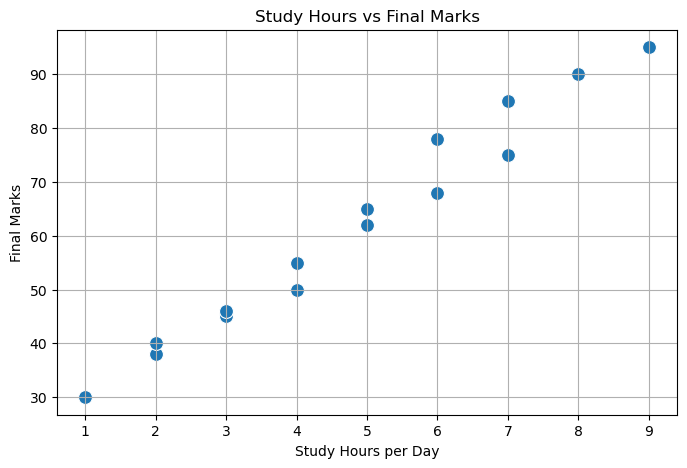

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="StudyHours",
    y="FinalMarks",
    s=100
)

plt.title("Study Hours vs Final Marks")
plt.xlabel("Study Hours per Day")
plt.ylabel("Final Marks")
plt.grid(True)
plt.show()

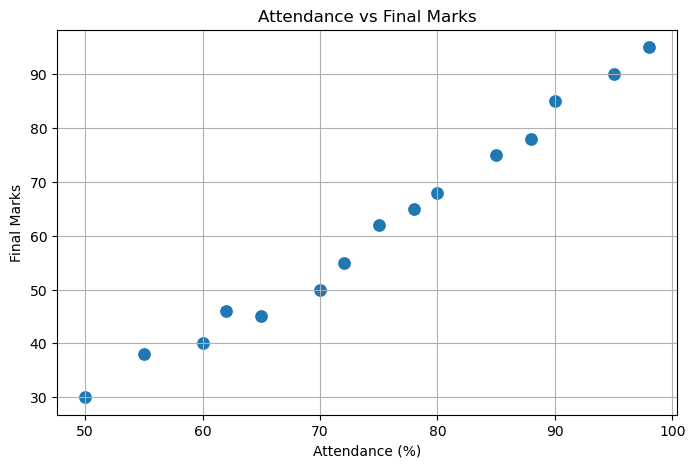

In [7]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Attendance",
    y="FinalMarks",
    s=100
)

plt.title("Attendance vs Final Marks")
plt.xlabel("Attendance (%)")
plt.ylabel("Final Marks")
plt.grid(True)
plt.show()

In [8]:

X = df[
    [
        "StudyHours",
        "Attendance",
        "PreviousMarks",
        "AssignmentsCompleted"
    ]
]


y = df["FinalMarks"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 12
Testing records: 3


In [9]:

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)


model.fit(X_train, y_train)

print("AI model trained successfully!")

AI model trained successfully!


In [10]:

predictions = model.predict(X_test)


mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("Actual marks:", list(y_test))
print("Predicted marks:", predictions.round(2))
print("Mean Absolute Error:", round(mae, 2))
print("R² Score:", round(r2, 2))

Actual marks: [55, 95, 30]
Predicted marks: [52.43 87.43 39.71]
Mean Absolute Error: 6.62
R² Score: 0.93


In [11]:

study_hours = 4
attendance = 75
previous_marks = 60
assignments_completed = 7

new_student = pd.DataFrame({
    "StudyHours": [study_hours],
    "Attendance": [attendance],
    "PreviousMarks": [previous_marks],
    "AssignmentsCompleted": [assignments_completed]
})

predicted_marks = model.predict(new_student)[0]

print("STUDENT PERFORMANCE PREDICTION")
print("------------------------------")
print("Study Hours:", study_hours)
print("Attendance:", attendance, "%")
print("Previous Marks:", previous_marks)
print("Assignments Completed:", assignments_completed)
print("Predicted Final Marks:", round(predicted_marks, 2))

STUDENT PERFORMANCE PREDICTION
------------------------------
Study Hours: 4
Attendance: 75 %
Previous Marks: 60
Assignments Completed: 7
Predicted Final Marks: 58.29


In [12]:
def performance_category(marks):
    if marks >= 80:
        return "Excellent"
    elif marks >= 70:
        return "Good"
    elif marks >= 50:
        return "Average"
    else:
        return "Needs Academic Support"

category = performance_category(predicted_marks)

print("Predicted Performance Category:", category)

Predicted Performance Category: Average


In [14]:


print("=" * 40)
print(" STUDENT PERFORMANCE DASHBOARD")
print("=" * 40)

print("\nTotal Students:", len(df))
print("Average Final Marks:", round(df["FinalMarks"].mean(), 2))
print("Average Attendance:", round(df["Attendance"].mean(), 2), "%")
print("Average Study Hours:", round(df["StudyHours"].mean(), 2))

print("\nHighest Final Marks:", df["FinalMarks"].max())
print("Lowest Final Marks:", df["FinalMarks"].min())

print("=" * 40)

 STUDENT PERFORMANCE DASHBOARD

Total Students: 15
Average Final Marks: 61.47
Average Attendance: 74.87 %
Average Study Hours: 4.8

Highest Final Marks: 95
Lowest Final Marks: 30


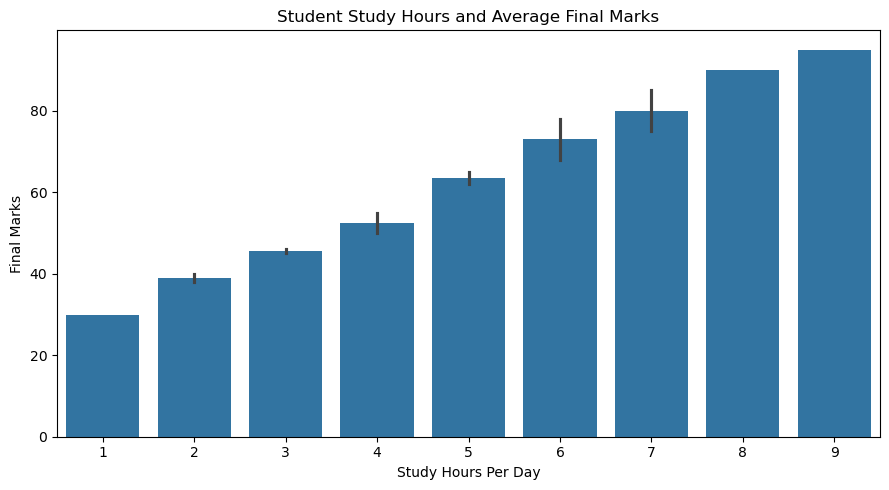

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="StudyHours",
    y="FinalMarks"
)

plt.title("Student Study Hours and Average Final Marks")
plt.xlabel("Study Hours Per Day")
plt.ylabel("Final Marks")
plt.tight_layout()
plt.show()

In [16]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [17]:
import streamlit as st

print("Streamlit installed successfully!")

Streamlit installed successfully!


In [18]:

import joblib

joblib.dump(model, "student_performance_model.pkl")

print("AI model saved successfully!")


AI model saved successfully!


In [19]:

df.to_csv("student_data.csv", index=False)

print("Student dataset saved successfully!")


Student dataset saved successfully!


In [ ]:
python -m streamlit run app.py